## Другий раз підбор параметра parallelCutoff після того як підібрали розміри блоків для 
**Зафіксовані параметри під час підбору:**

- `threshold` (базовий випадок в послідовному): 8192
- `partitionBlock` (розмір 1 блоку для паралельного розбиття): 8192
- `filterBlock` (розмір 1 блоку для паралельної фільтрації): 2048
- `parallelSortCutoff` (поріг, коли включається паралельне сортування): 0 — значить, що паралельного сортування не буде

`parallelCutoff` підбирався на параметрах: 32768, 65536, 131072, 262144

### Обране фінальне значення parallelCutoff: `65536`

In [1]:
# Дані
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df1 = pd.read_csv("C:/Users/admin/source/repos/Kruskal/results/fk_par_cutoff2.csv")
df2 = pd.read_csv("C:/Users/admin/source/repos/Kruskal/results/fk_par_cutoff.csv")
result = pd.concat([df2[df2["algorithm"] == "fk"], df1], ignore_index=True)
MIN_EDGES = 1_000_000         

In [3]:
df = result.copy()
order = list(df["graph"].unique()) 

In [9]:
# Параметри досліду
PARAMS = ["threads", "threshold", "partition_block", "filter_block", "par_cutoff", "psort_cutoff"]

def experiment_params(df):
    rows = {}
    for alg, d in df.groupby("algorithm", sort=False):
        row = {}
        for c in PARAMS:
            vals = sorted(d[c].dropna().unique())
            row[c] = ", ".join(str(int(v)) for v in vals) if vals else "-"
        repeats = d.groupby(["graph"] + PARAMS, dropna=False)["repeat"].nunique()
        row["повторів"] = f"{repeats.min()}–{repeats.max()}" if repeats.min() != repeats.max() else str(repeats.min())
        rows[alg] = row
    graphs = df["graph"].unique()
    print(f"Графи ({len(graphs)}): {', '.join(graphs)}")
    return pd.DataFrame(rows).T

display(experiment_params(df))

Графи (19): B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11, G1, C1, C2, C3, C4, C5, C6, C7


,threads,threshold,partition_block,filter_block,par_cutoff,psort_cutoff,повторів
fk,1,8192,-,-,-,-,6–25
fk-par,12,8192,8192,2048,"32768, 65536, 131072, 262144",0,7–25


In [4]:
# %% 1. Середній час: послідовний FK і fk-par для кожного порогу
seq = df[df["algorithm"] == "fk"].groupby("graph")["total_ms"].mean()

par = df[df["algorithm"] == "fk-par"].copy()
par["par_cutoff"] = par["par_cutoff"].astype(int)
t = par.groupby(["graph", "E", "par_cutoff"], as_index=False)["total_ms"].mean()

t["speedup"] = t["graph"].map(seq) / t["total_ms"]                          # прискорення відносно послідовного FK
t["rel"] = t["total_ms"] / t.groupby("graph")["total_ms"].transform("min")   # 1.00 = найкращий поріг на графі

print("Середній час fk-par, мс:")
display(t.pivot(index="graph", columns="par_cutoff", values="total_ms").reindex(order).round(1))

Середній час fk-par, мс:


par_cutoff,32768,65536,131072,262144
graph,,,,
B1,0.8,0.8,0.8,0.8
B2,1.0,1.0,1.0,1.0
B3,1.7,1.6,1.6,1.5
B4,2.4,2.5,2.3,2.3
B5,3.5,3.4,3.8,3.6
B6,5.5,5.6,5.6,6.7
B7,9.2,9.4,9.5,10.6
B8,17.5,17.6,17.9,18.5
B9,33.6,33.6,33.9,34.4


In [5]:
print("Прискорення відносно послідовного FK:")
display(t.pivot(index="graph", columns="par_cutoff", values="speedup").reindex(order).round(2))

Прискорення відносно послідовного FK:


par_cutoff,32768,65536,131072,262144
graph,,,,
B1,1.10,1.10,1.10,1.10
B2,1.13,1.12,1.12,1.12
B3,0.92,0.99,0.99,1.02
B4,0.96,0.94,1.01,1.04
B5,1.00,1.02,0.91,0.98
B6,1.19,1.17,1.17,0.99
B7,1.32,1.30,1.29,1.16
B8,1.45,1.45,1.42,1.38
B9,1.43,1.43,1.42,1.40


In [6]:
# Висновок: лише великі графи
big = t[t["E"] >= MIN_EDGES]
print(f"Графи з E >= {MIN_EDGES:,}: {', '.join(g for g in order if g in set(big['graph']))}")

rel_table = big.pivot(index="graph", columns="par_cutoff", values="rel").reindex([g for g in order if g in set(big['graph'])])
print("Відносний час (1.00 = найкращий поріг на цьому графі):")
display(rel_table.round(3))

Графи з E >= 1,000,000: B7, B8, B9, B10, B11, G1, C4, C5, C6, C7
Відносний час (1.00 = найкращий поріг на цьому графі):


par_cutoff,32768,65536,131072,262144
graph,,,,
B7,1.000,1.020,1.029,1.144
B8,1.000,1.007,1.022,1.057
B9,1.000,1.000,1.007,1.024
B10,1.003,1.000,1.005,1.016
B11,1.000,1.001,1.011,1.010
G1,1.046,1.000,1.033,1.062
C4,1.078,1.053,1.000,1.017
C5,1.042,1.068,1.000,1.091
C6,1.035,1.000,1.055,1.059


In [7]:
summary = (big.groupby("par_cutoff")["rel"]
              .agg(середнє_відставання=lambda r: np.exp(np.log(r).mean()),   # середнє геометричне
                   найгірший_граф="max",
                   перемог=lambda r: int((r == 1.0).sum()))
              .sort_values("середнє_відставання"))
display(summary.round(3))

,середнє_відставання,найгірший_граф,перемог
par_cutoff,,,
65536,1.015,1.068,4
131072,1.019,1.055,2
32768,1.021,1.078,4
262144,1.053,1.144,0


In [8]:
best = summary.index[0]
print(f"\nНайкращий поріг паралельності: {best}")
print(f"Він повільніший за найкращий на кожному графі в середньому на {100 * (summary.iloc[0, 0] - 1):.1f}%")
if 262144 in summary.index:
    gap = 100 * (summary.loc[131072, "середнє_відставання"] / summary.iloc[0, 0] - 1)
    print(f"Поточне значення 131072 гірше за найкраще на {gap:.1f}%")



Найкращий поріг паралельності: 65536
Він повільніший за найкращий на кожному графі в середньому на 1.5%
Поточне значення 131072 гірше за найкраще на 0.4%


In [9]:
noise = (par[par["E"] >= MIN_EDGES].groupby(["graph", "par_cutoff"])["total_ms"]
            .agg(lambda x: x.std() / x.mean()).median() * 100)
print(f"Типовий розкид між повторами: {noise:.1f}%  (різниця, менша за нього — це шум)")

Типовий розкид між повторами: 1.5%  (різниця, менша за нього — це шум)


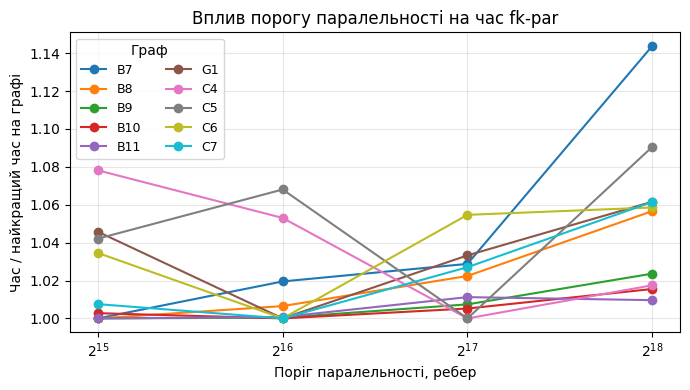

In [11]:
# %% 3. Графік: відносний час від порогу для кожного великого графа
fig, ax = plt.subplots(figsize=(7, 4))
for graph, row in rel_table.iterrows():
    ax.plot(row.index, row.values, marker="o", label=graph)
ax.set_xscale("log", base=2)
ax.set_xticks(rel_table.columns)
ax.set_xlabel("Поріг паралельності, ребер")
ax.set_ylabel("Час / найкращий час на графі")
ax.set_title("Вплив порогу паралельності на час fk-par")
ax.grid(alpha=0.3)
ax.legend(title="Граф", ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("C:/Users/admin/source/repos/Kruskal/results/fk_par_cutoff.png", dpi=150)
plt.show()